# Prueba de Dispersión / Varianza entre Hombres y Mujeres 
Se evalúa la variabilidad/dispersión y no solo las medias.
- Hipótesis nula ($H_0$): La dispersión (variabilidad) salarial entre hombres y mujeres es igual ($\sigma_h^2 = \sigma_m^2$).
- Hipótesis alternativa ($H_1$): La dispersión salarial cambia entre hombres y mujeres ($\sigma_h^2 \neq \sigma_m^2$).

In [1]:
import numpy as np
import pandas as pd
import scipy.integrate as integrate
from scipy.special import gamma as gamma
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 1. Distribución F 
def Fdist(f, nu1, nu2):
    return gamma((nu1 + nu2) * 0.5) * (nu1 / nu2) ** (nu1 * 0.5) / (gamma(nu1 * 0.5) * gamma(nu2 * 0.5)) * f**(nu1 * 0.5 - 1.0) / (1.0 + nu1 * f / nu2)**((nu1 + nu2) * 0.5)

In [3]:
# Cargar dataset
df = pd.read_csv("../data/processed/docentes_enoe_sin_anomalias.csv", low_memory=False)

# Limpiar y preparar variables
df["ingocup"] = pd.to_numeric(df["ingocup"], errors="coerce")
df["sex"] = pd.to_numeric(df["sex"], errors="coerce")
df_clean = df.dropna(subset=["ingocup", "sex"]).copy()
df_clean = df_clean[df_clean["ingocup"] > 0]

In [5]:
def prueba_dispersion():
    print("=== PRUEBA 3: DISPERSIÓN / VARIANZA SALARIAL ENTRE HOMBRES Y MUJERES ===")

    # Cargar dataset
    df = pd.read_csv("../data/processed/docentes_enoe_sin_anomalias.csv", low_memory=False)

    # Limpiar y preparar variables
    df["ingocup"] = pd.to_numeric(df["ingocup"], errors="coerce")
    df["sex"] = pd.to_numeric(df["sex"], errors="coerce")
    df_clean = df.dropna(subset=["ingocup", "sex"]).copy()
    df_clean = df_clean[df_clean["ingocup"] > 0]

    # Separar salarios por género (Hombres: sex == 1, Mujeres: sex == 2)
    salarios_hombres = df_clean[df_clean["sex"] == 1]["ingocup"].values
    salarios_mujeres = df_clean[df_clean["sex"] == 2]["ingocup"].values

    n_hombres = len(salarios_hombres)
    n_mujeres = len(salarios_mujeres)

    # Estadísticos de dispersión (Varianza muestral s^2)
    var_hombres = np.var(salarios_hombres, ddof=1)
    var_mujeres = np.var(salarios_mujeres, ddof=1)
    std_hombres = np.std(salarios_hombres, ddof=1)
    std_mujeres = np.std(salarios_mujeres, ddof=1)

    # Estadístico F de cociente de varianzas
    f_calc = var_mujeres / var_hombres
    
    v1 = n_mujeres - 1
    v2 = n_hombres - 1

    # Búsqueda del valor crítico F 
    alpha = 0.05
    f_arr = np.linspace(0.01, 5, 10000)
    f_critico = None

    for fval in f_arr:
        prob, _ = integrate.quad(lambda x: stats.f.pdf(x, v1, v2), fval, np.inf)
        if prob <= (alpha / 2):  # Prueba bilateral
            f_critico = fval
            break
            
    # Definir límites críticos bilaterales
    f_crit_inf = 1.0 / f_critico
    f_crit_sup = f_critico

    print(f"Hombres (n = {n_hombres}) - Varianza: {var_hombres:,.2f} | Desv. Est: {std_hombres:,.2f}")
    print(f"Mujeres (n = {n_mujeres}) - Varianza: {var_mujeres:,.2f} | Desv. Est: {std_mujeres:,.2f}")
    print(f"Grados de libertad: v1 = {v1}, v2 = {v2}")
    print(f"Estadístico F calculado (Cociente de varianzas): {f_calc:.4f}")
    print(f"Valores críticos F, alpha={alpha}): [{f_crit_inf:.4f}, {f_crit_sup:.4f}]")

    print("\n--- Conclusión de la Prueba de Dispersión ---")
    print("H0: La dispersión salarial entre hombres y mujeres es igual (sigma_h^2 = sigma_m^2).")
    print("H1: La dispersión salarial cambia entre hombres y mujeres (sigma_h^2 != sigma_m^2).")
    
    if f_calc > f_crit_sup or f_calc < f_crit_inf:
        print(f"Como F_calc ({f_calc:.4f}) cae fuera del intervalo crítico [{f_crit_inf:.4f}, {f_crit_sup:.4f}], se RECHAZA la H0.")
        print("Conclusión: La dispersión y variabilidad de los salarios cambia de manera estadísticamente significativa entre géneros.")
    else:
        print(f"Como F_calc ({f_calc:.4f}) está dentro del intervalo crítico, NO se rechaza la H0.")
        print("Conclusión: No hay evidencia suficiente para afirmar que la dispersión salarial difiere entre géneros.")

prueba_dispersion()

=== PRUEBA 3: DISPERSIÓN / VARIANZA SALARIAL ENTRE HOMBRES Y MUJERES ===
Hombres (n = 397) - Varianza: 33,560,915.02 | Desv. Est: 5,793.18
Mujeres (n = 750) - Varianza: 33,952,921.79 | Desv. Est: 5,826.91
Grados de libertad: v1 = 749, v2 = 396
Estadístico F calculado (Cociente de varianzas): 1.0117
Valores críticos F, alpha=0.05): [0.8395, 1.1913]

--- Conclusión de la Prueba de Dispersión ---
H0: La dispersión salarial entre hombres y mujeres es igual (sigma_h^2 = sigma_m^2).
H1: La dispersión salarial cambia entre hombres y mujeres (sigma_h^2 != sigma_m^2).
Como F_calc (1.0117) está dentro del intervalo crítico, NO se rechaza la H0.
Conclusión: No hay evidencia suficiente para afirmar que la dispersión salarial difiere entre géneros.


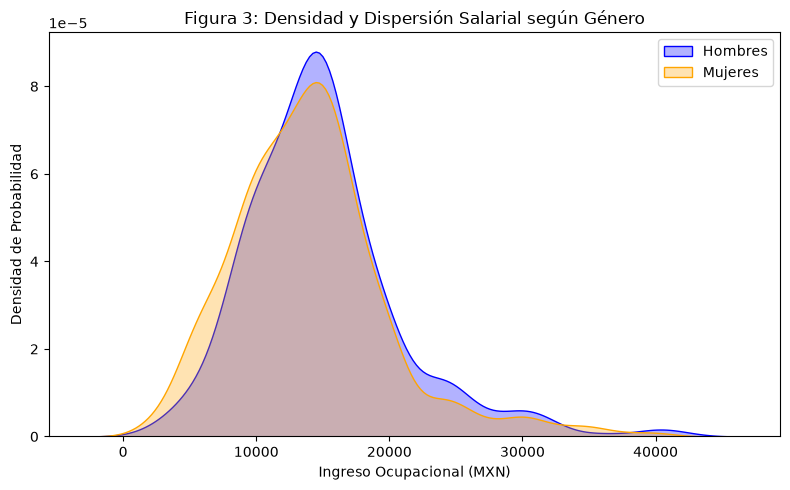

In [6]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df_clean[df_clean['sex'] == 1], x='ingocup', label='Hombres', fill=True, color='blue', alpha=0.3)
sns.kdeplot(data=df_clean[df_clean['sex'] == 2], x='ingocup', label='Mujeres', fill=True, color='orange', alpha=0.3)
plt.title('Figura 3: Densidad y Dispersión Salarial según Género')
plt.xlabel('Ingreso Ocupacional (MXN)')
plt.ylabel('Densidad de Probabilidad')
plt.legend()
plt.tight_layout()
plt.savefig('../outputs/figures/dispersion_genero.png', dpi=300)
plt.show()